# Sparklines : des mini-graphiques dans les cellules d'un DataFrame

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moncoachdata/MonShotData/blob/main/Pandas/Sparklines-DataFrame.ipynb)

📖 **Le shot complet** : [Sparklines : ces mini-graphiques sous-cotés qui transforment tes DataFrames](https://www.monshotdata.com/p/sparklines-visualisation-donnees)

---

Un **sparkline** est un tout petit graphique, sans axes ni légende, qui tient dans une cellule de tableau. Il donne la tendance d'un coup d'œil, là où une colonne de nombres demande de tout lire. Ici tu en intègres dans un DataFrame Pandas : un graphique linéaire coloré selon la tendance, et un histogramme.

**À la fin de ce notebook, tu sauras :**

- dessiner un mini-graphique avec Matplotlib, sans axes, et le convertir en image encodée en **base64** ;
- insérer cette image dans une cellule de DataFrame avec une balise HTML `<img>` ;
- afficher le DataFrame avec `to_html(escape=False)` pour que les images apparaissent au lieu du texte brut.

### Avant de lancer

- **Installation** : rien : Pandas, NumPy et Matplotlib sont déjà là dans Colab et Jupyter.
- **Les données** : des historiques de prix **fictifs** pour quatre tickers (AAPL, MSFT, GOOG, META), générés avec une graine fixée : les mêmes graphiques à chaque exécution. Ce ne sont pas de vrais cours.
- **Où ça s'affiche** : le tableau avec les images s'affiche dans Jupyter, JupyterLab et Colab. Sur GitHub, l'aperçu du notebook peut ne pas montrer les images intégrées au HTML : ouvre le notebook dans Colab.

🧪 *Testé le 22 novembre 2026 : exécution complète de haut en bas (Python 3.13, Pandas 3.0, NumPy 2.5 et Matplotlib 3.11). Les sorties affichées viennent de cette exécution.*

## 1. Mise en place

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from base64 import b64encode
from io import BytesIO
from IPython.display import HTML

colors = ['#fe7c73', '#2471A3', '#3498DB', '#27AE60']   # rouge, bleu foncé, bleu clair, vert

## 2. Les données

Chaque ticker a un historique de 100 prix, simulé par une marche aléatoire à partir d'un prix de départ. Le DataFrame contient une ligne par ticker, et la colonne `Historique des prix` contient **une liste de 100 valeurs** par cellule.

In [2]:
rng = np.random.default_rng(17)   # graine fixée : mêmes graphiques à chaque exécution

def simule_prix(depart, n=100):
    # variations quotidiennes d'environ 2 % : chaque prix part du précédent
    rendements = rng.normal(loc=0, scale=0.02, size=n)
    return depart * np.cumprod(1 + rendements)

df = pd.DataFrame(
    [("AAPL", simule_prix(200)),
     ("MSFT", simule_prix(400)),
     ("GOOG", simule_prix(170)),
     ("META", simule_prix(550))],
    columns=["Nom", "Historique des prix"],
)

df["Nom"].tolist(), len(df.loc[0, "Historique des prix"])

(['AAPL', 'MSFT', 'GOOG', 'META'], 100)

## 3. Le principe : un graphique devient du texte

Une cellule de DataFrame ne peut pas contenir une figure Matplotlib. Mais Jupyter sait afficher du HTML, et une balise `<img>` peut contenir une image **encodée en texte** (base64) directement dans l'attribut `src`. La recette :

1. dessiner la figure, sans axes ;
2. l'enregistrer **en mémoire** (un objet `BytesIO`, pas de fichier sur le disque) ;
3. encoder ces octets en base64, puis en texte ;
4. renvoyer la balise `<img src="data:image/png;base64,...">`.

## 4. Sparkline en graphique linéaire

La couleur indique la tendance : **rouge** si le dernier prix est inférieur au premier, **vert** sinon. Un point marque la dernière valeur.

In [3]:
def create_line(data):
    data = list(data)

    # Figure minuscule : 2 pouces de large, 0,5 de haut, fond transparent
    fig, ax = plt.subplots(figsize=(2, 0.5), facecolor="none")

    # Rouge si le prix a baissé sur la période, vert sinon
    couleur = colors[0] if data[0] > data[-1] else colors[3]

    ax.plot(data, color=couleur)
    ax.axis("off")   # ni axes, ni graduations, ni cadre

    # Marqueur sur le dernier point
    ax.plot(len(data) - 1, data[-1], ".", color=couleur)

    plt.close(fig)   # évite d'afficher la figure dans la cellule

    # Enregistre la figure en PNG en mémoire, puis l'encode en base64
    img = BytesIO()
    fig.savefig(img, format="png")
    encoded = b64encode(img.getvalue()).decode("utf-8")

    return f'<img src="data:image/png;base64,{encoded}"/>'

On peut déjà regarder ce que renvoie la fonction : c'est une longue chaîne de texte, pas une image.

In [4]:
html = create_line(df.loc[0, "Historique des prix"])
print(len(html), "caractères")
print(html[:80] + "...")

6523 caractères
<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAZAAAABkCAYAAACoy2Z3AAAA...


## 5. Sparkline en histogramme

Même principe, avec la distribution des valeurs plutôt que leur évolution. Attention à la balise : le type d'image doit être écrit `data:image/png;base64,...` en entier.

In [5]:
def create_hist(data):
    fig, ax = plt.subplots(figsize=(2, 0.5), facecolor="none")

    ax.hist(data, bins=10, color=colors[2])
    ax.axis("off")
    plt.close(fig)

    img = BytesIO()
    fig.savefig(img, format="png")
    encoded = b64encode(img.getvalue()).decode("utf-8")

    return f'<img src="data:image/png;base64,{encoded}"/>'

## 6. Ajouter les sparklines au DataFrame

`apply` appelle chaque fonction sur la liste de prix de chaque ligne, et range les balises HTML dans de nouvelles colonnes.

In [6]:
df["Prix journaliers"] = df["Historique des prix"].apply(create_line)
df["Distribution des prix"] = df["Historique des prix"].apply(create_hist)

df.drop(columns="Historique des prix").head()

,Nom,Prix journaliers,Distribution des prix
0,AAPL,"<img src=""data:image/png;base64,iVBORw0KGgoAAA...","<img src=""data:image/png;base64,iVBORw0KGgoAAA..."
1,MSFT,"<img src=""data:image/png;base64,iVBORw0KGgoAAA...","<img src=""data:image/png;base64,iVBORw0KGgoAAA..."
2,GOOG,"<img src=""data:image/png;base64,iVBORw0KGgoAAA...","<img src=""data:image/png;base64,iVBORw0KGgoAAA..."
3,META,"<img src=""data:image/png;base64,iVBORw0KGgoAAA...","<img src=""data:image/png;base64,iVBORw0KGgoAAA..."


Sans précaution, Pandas affiche les balises comme du **texte brut** : c'est le comportement normal, car `DataFrame.to_html` échappe par défaut les caractères `<` et `>` pour éviter d'injecter du HTML. Il faut le lui demander explicitement :

## 7. Afficher les images

`to_html(escape=False)` laisse passer les balises, et `HTML(...)` demande à Jupyter de les interpréter.

,Nom,Prix journaliers,Distribution des prix
0,AAPL,,
1,MSFT,,
2,GOOG,,
3,META,,

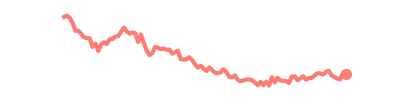
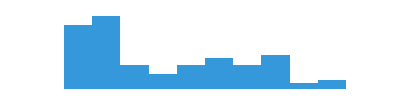
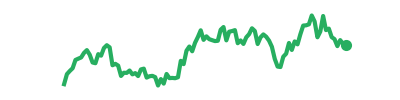
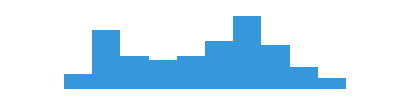
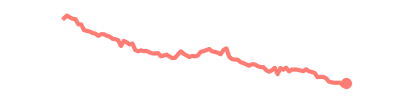
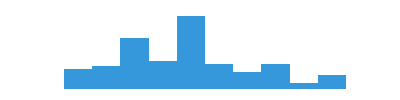
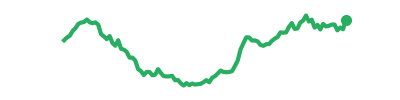
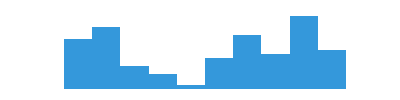

In [7]:
HTML(df.drop(columns="Historique des prix").to_html(escape=False))

Chaque ligne a maintenant son mini-graphique : la couleur donne la tendance (rouge en baisse, vert en hausse), le point marque le dernier prix, et l'histogramme montre où se concentrent les valeurs.

> Remarque : l'histogramme des prix n'a de sens que pour la distribution. Avec de vraies données, tu pourrais afficher à la place un autre indicateur, comme le volume échangé par heure, si tu as la colonne correspondante.

## 8. Attention : `escape=False` et sécurité

`escape=False` désactive la protection de Pandas : tout le contenu des cellules est interprété comme du HTML. Utilise-le seulement sur des données que **tu as créées toi-même**, comme ici. Si le DataFrame contient du texte venant d'utilisateurs ou d'internet, du HTML malveillant pourrait s'exécuter dans ta page.

## 9. Ce qu'il faut retenir

- Un sparkline est un mini-graphique sans axes qui s'intègre dans une cellule de tableau pour montrer une tendance d'un coup d'œil.
- Principe : figure Matplotlib minuscule, enregistrée en mémoire avec `BytesIO`, encodée en base64, insérée dans une balise `<img src="data:image/png;base64,...">`.
- `apply` range cette balise dans une colonne, une cellule par ligne.
- Pour que les images s'affichent, utilise `HTML(df.to_html(escape=False))`. Par défaut, Pandas échappe le HTML.
- `escape=False` n'est sûr que sur des données que tu as créées toi-même.

---

## Pour aller plus loin

- [Pandas : intégrer des graphiques dans les cellules d'un DataFrame](https://www.monshotdata.com/p/une-facon-moins-connue-de-creer-des-graphes-avec-pandas) — une autre façon de mettre des graphiques dans un tableau
- [Rends tes graphiques plus parlants !](https://www.monshotdata.com/p/graphiques-annotes) — annoter tes graphiques pour guider le regard
- [De jolis tracés interactifs avec Pandas](https://www.monshotdata.com/p/backend-plotly-avec-pandas) — des graphiques interactifs avec le backend Plotly
- [Tous les notebooks des shots](https://github.com/moncoachdata/MonShotData) — le code Python de la newsletter, rangé par thème